In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
from typing import Dict, Tuple
import os

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})


outpath='./CV_summary/' # CV = cross-validation


In [3]:
datatypes = ['CS', 'S$^2', 'NOE', 'RDC', 'J-coupling']
dataname = ['CS', 'S2', 'NOE', 'RDC', 'Jcoupling']
directories = ['CS_analyses', 'S2_analyses_nonblockHDXrew', 'NOE_analyses', 'RDC_analyses', 'Jcoupling_analyses' ]

models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled', 
          'rewM10', 'rewM10DH', 'rewM10DH_scaled', 'rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH', 'rewM12DH_scaled', 'rewM14', 'rewM14DH', 'rewM14DH_scaled']

proteins = [['alpha3D','Barnase', 'BarstarK60', 'betalactamasePSE4', 'BPTI', 'Calmodulin', 'CI2', 'DAXX', 'FKBP12', 'GB3'
            , 'HIVintegrase', 'HP36', 'Im7', 'Jarastatin', 'lDHFR','Lysozyme', 'PeroxiredoxinQ',  'SAMP1', 'Staph_nuclease_P117G_H124L', 'T4_lysozyme',  'Ubiquitin'],
            ['alpha3D', 'Barnase', 'betalactamasePSE4', 'CI2', 'FKBP12', 'GB3', 'HIVintegrase', 'HP36', 'Im7', 'Jarastatin', 'Lysozyme', 'PeroxiredoxinQ', 'Ubiquitin'],
            ['ACP', 'GB3', 'HP36', 'Jarastatin', 'lDHFR', 'Lysozyme', 'SAMP1', 'Ubiquitin'],
            ['GB3', 'Lysozyme', 'Ubiquitin'],
            ['BPTI', 'GB3', 'Ubiquitin']]



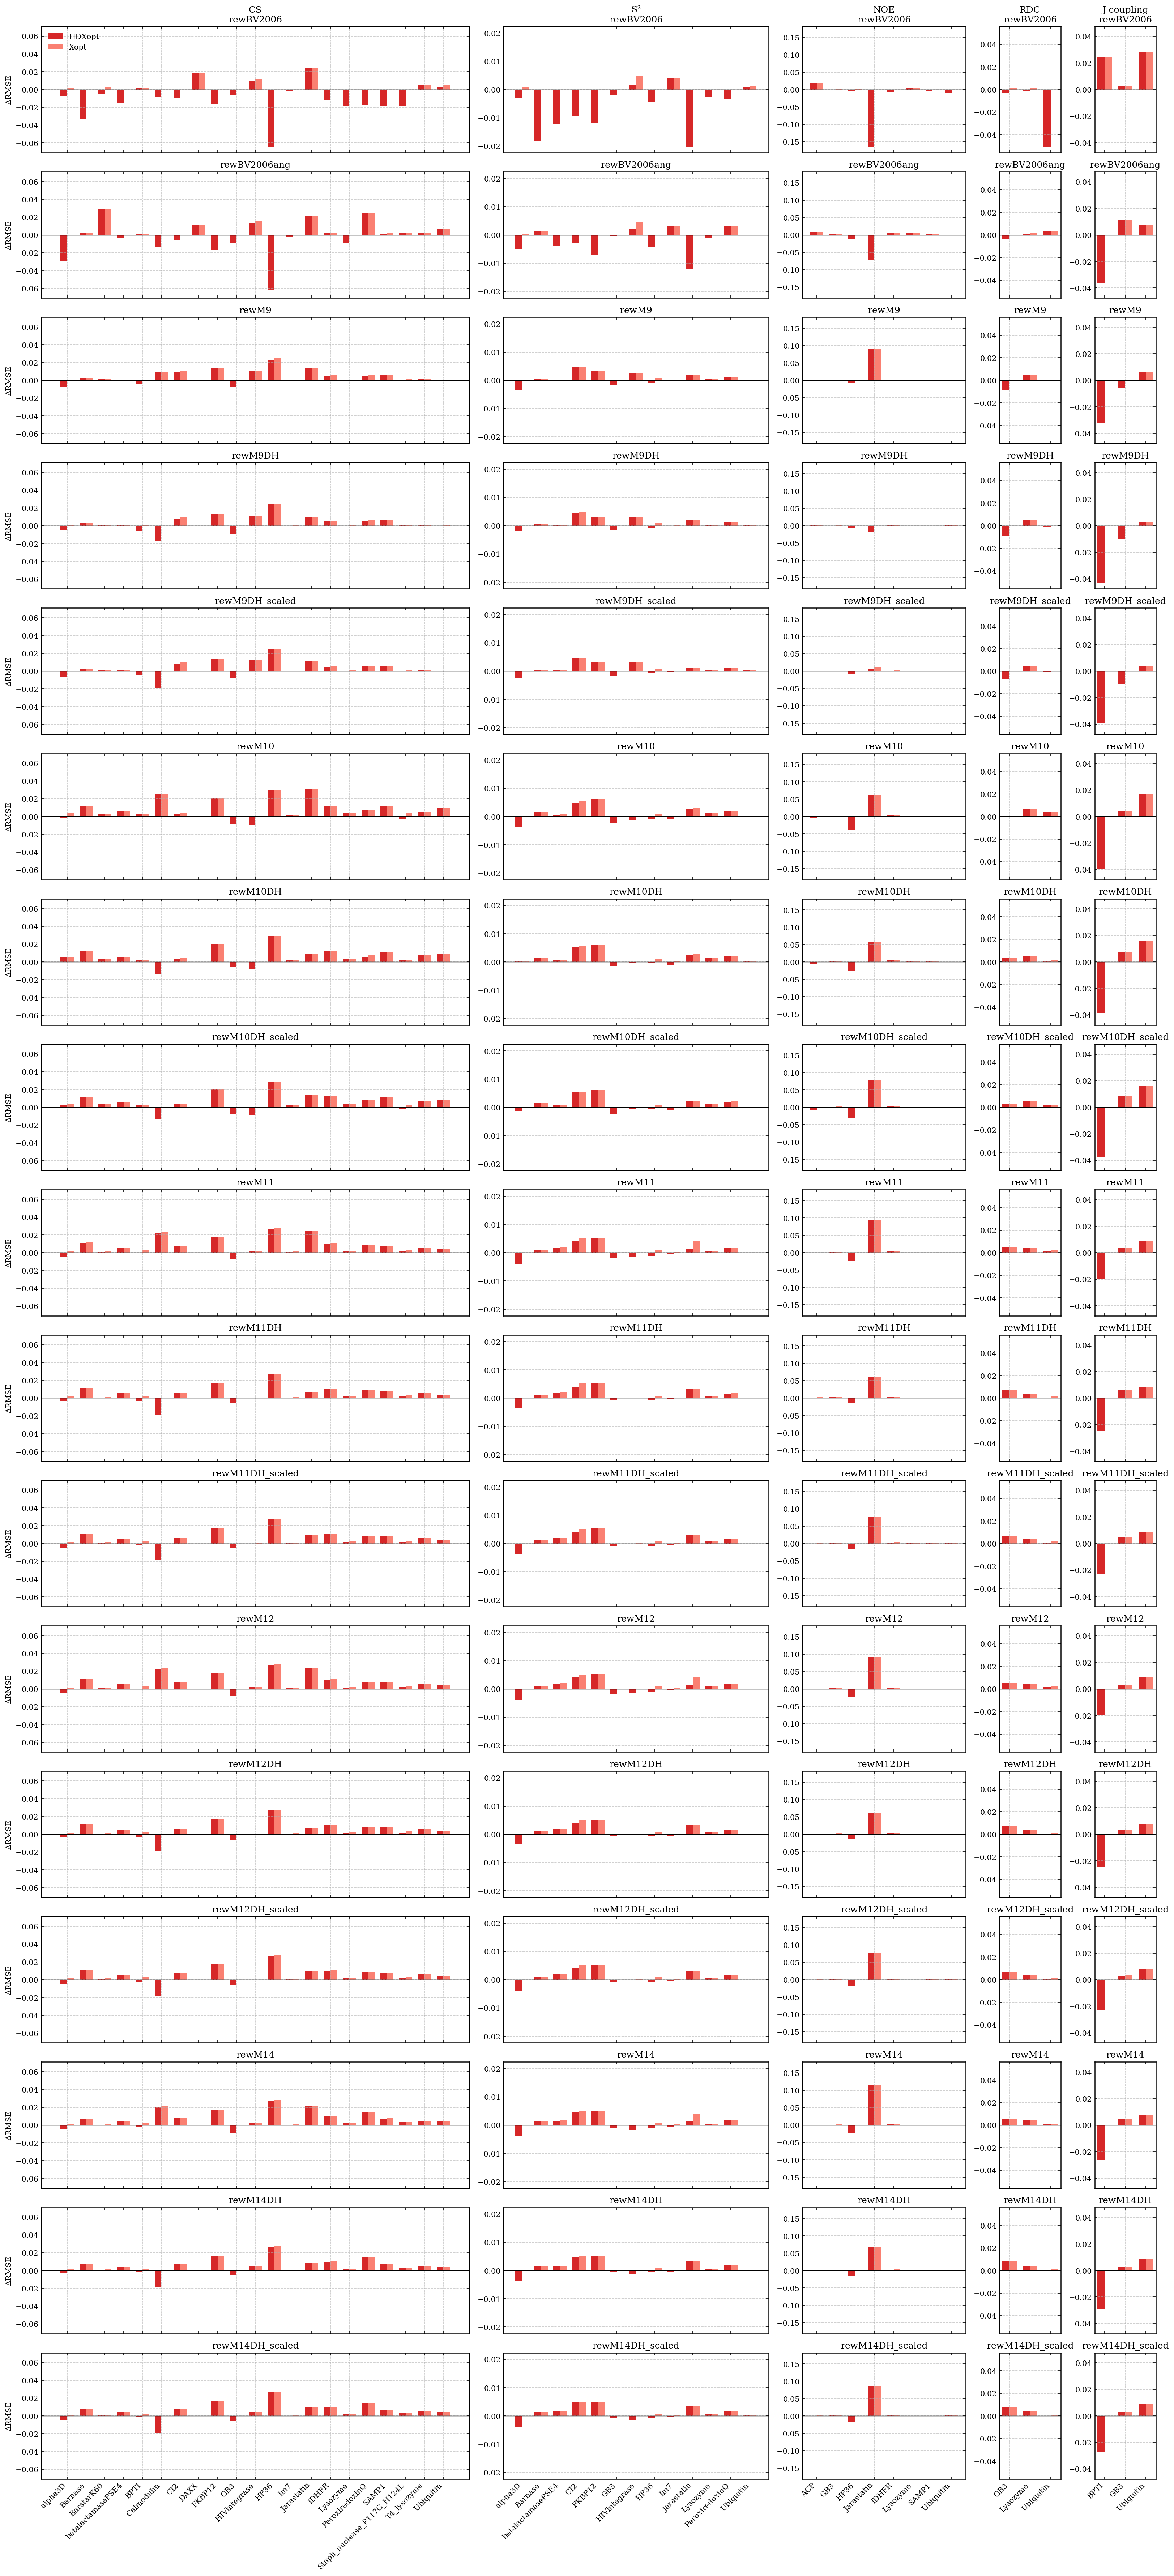

In [20]:


# ---------------------------------------------------------
# Lists
# ---------------------------------------------------------
datatypes = ['CS', 'S$^2$', 'NOE', 'RDC', 'J-coupling']
dataname = ['CS', 'S2', 'NOE', 'RDC', 'Jcoupling']
directories = ['CS_analyses', 'S2_analyses_nonblockHDXrew', 'NOE_analyses',
               'RDC_analyses', 'Jcoupling_analyses']


# ---------------------------------------------------------
# Compute ΔRMSE or ΔQ for each datatype
# ---------------------------------------------------------
all_df = {}

for dtype, dname, ddir, prot_list in zip(datatypes, dataname, directories, proteins):

    rows = []

    for model in models:
        for prot in prot_list:

            if dname == 'S2':
                file = f"{ddir}/{prot}_{model}_{dname}_validation_1xTAUR.csv"
            else:
                file = f"{ddir}/{prot}_{model}_{dname}_validation.csv"

            dat = pd.read_csv(file)

            metric = "Q" if dname == "RDC" else "RMSE"

            if dtype == "J-coupling":
                col = f"J_{metric}"
            else:
                col = f"{dname}_{metric}"

            prior = dat[col].iloc[0]
            post1 = dat[col].iloc[-1]
            post2 = dat[col].min()

            rows.append({
                "Model": model,
                "Protein": prot,
                "HDXopt": prior - post1,
                f"{dtype}opt": prior - post2,
                "metric": metric
            })

    all_df[dname] = pd.DataFrame(rows)

# ---------------------------------------------------------
# Figure with variable column widths
# ---------------------------------------------------------
n_models = len(models)
n_types  = len(datatypes)

width_ratios = [len(p) for p in proteins]  # each datatype column width proportional to protein count

fig, axes = plt.subplots(
    n_models, n_types,
    figsize=(sum(width_ratios) * 0.45, n_models * 2.8),
    gridspec_kw={"width_ratios": width_ratios},
    sharey=False
)

axes = np.atleast_2d(axes)

# ---------------------------------------------------------
# Fill subplots
# ---------------------------------------------------------
for c, (dtype, dname, prot_list) in enumerate(zip(datatypes, dataname, proteins)):

    df = all_df[dname]
    metric = df["metric"].iloc[0]
    ylabel = f"Δ{metric}"

    x = np.arange(len(prot_list))
    width = 0.35

    # -------- Symmetric y-range for this datatype --------
    raw_min = df[["HDXopt", f"{dtype}opt"]].min().min()
    raw_max = df[["HDXopt", f"{dtype}opt"]].max().max()
    max_abs = max(abs(raw_min), abs(raw_max)) * 1.1
    ymin, ymax = -max_abs, max_abs

    for r, model in enumerate(models):

        ax = axes[r, c]
        sub = df[df["Model"] == model]

        # Bars
        ax.bar(x - width/2, sub["HDXopt"],       width, color="tab:red", label = 'HDXopt')
        ax.bar(x + width/2, sub[f"{dtype}opt"],  width, color="salmon", label = 'Xopt')

        ax.axhline(0, color="black", linewidth=0.7)
        ax.set_ylim(ymin, ymax)

        # Grid for all rows
        ax.set_xticks(x)
        ax.grid(axis='x', linestyle='--', linewidth=0.4)

        # Only show tick labels on bottom row
        if r == n_models - 1:
            ax.set_xticklabels(prot_list, rotation=45, ha='right')
        else:
            ax.set_xticklabels([])

        # Titles
        avg_hdx = sub["HDXopt"].mean()
        avg_x   = sub[f"{dtype}opt"].mean()
        ax.set_title(model)
        if r == 0:
            ax.set_title(f"{dtype}\n{model}")

        # Y-label only once per row (left column)
        if c == 0:
            ax.set_ylabel(ylabel)

        # Legend once
        if r == 0 and c == 0:
            ax.legend(loc="upper left")

plt.tight_layout()
plt.savefig(outpath+'Folded_Proteins_Crossvalidation.png', dpi=300)


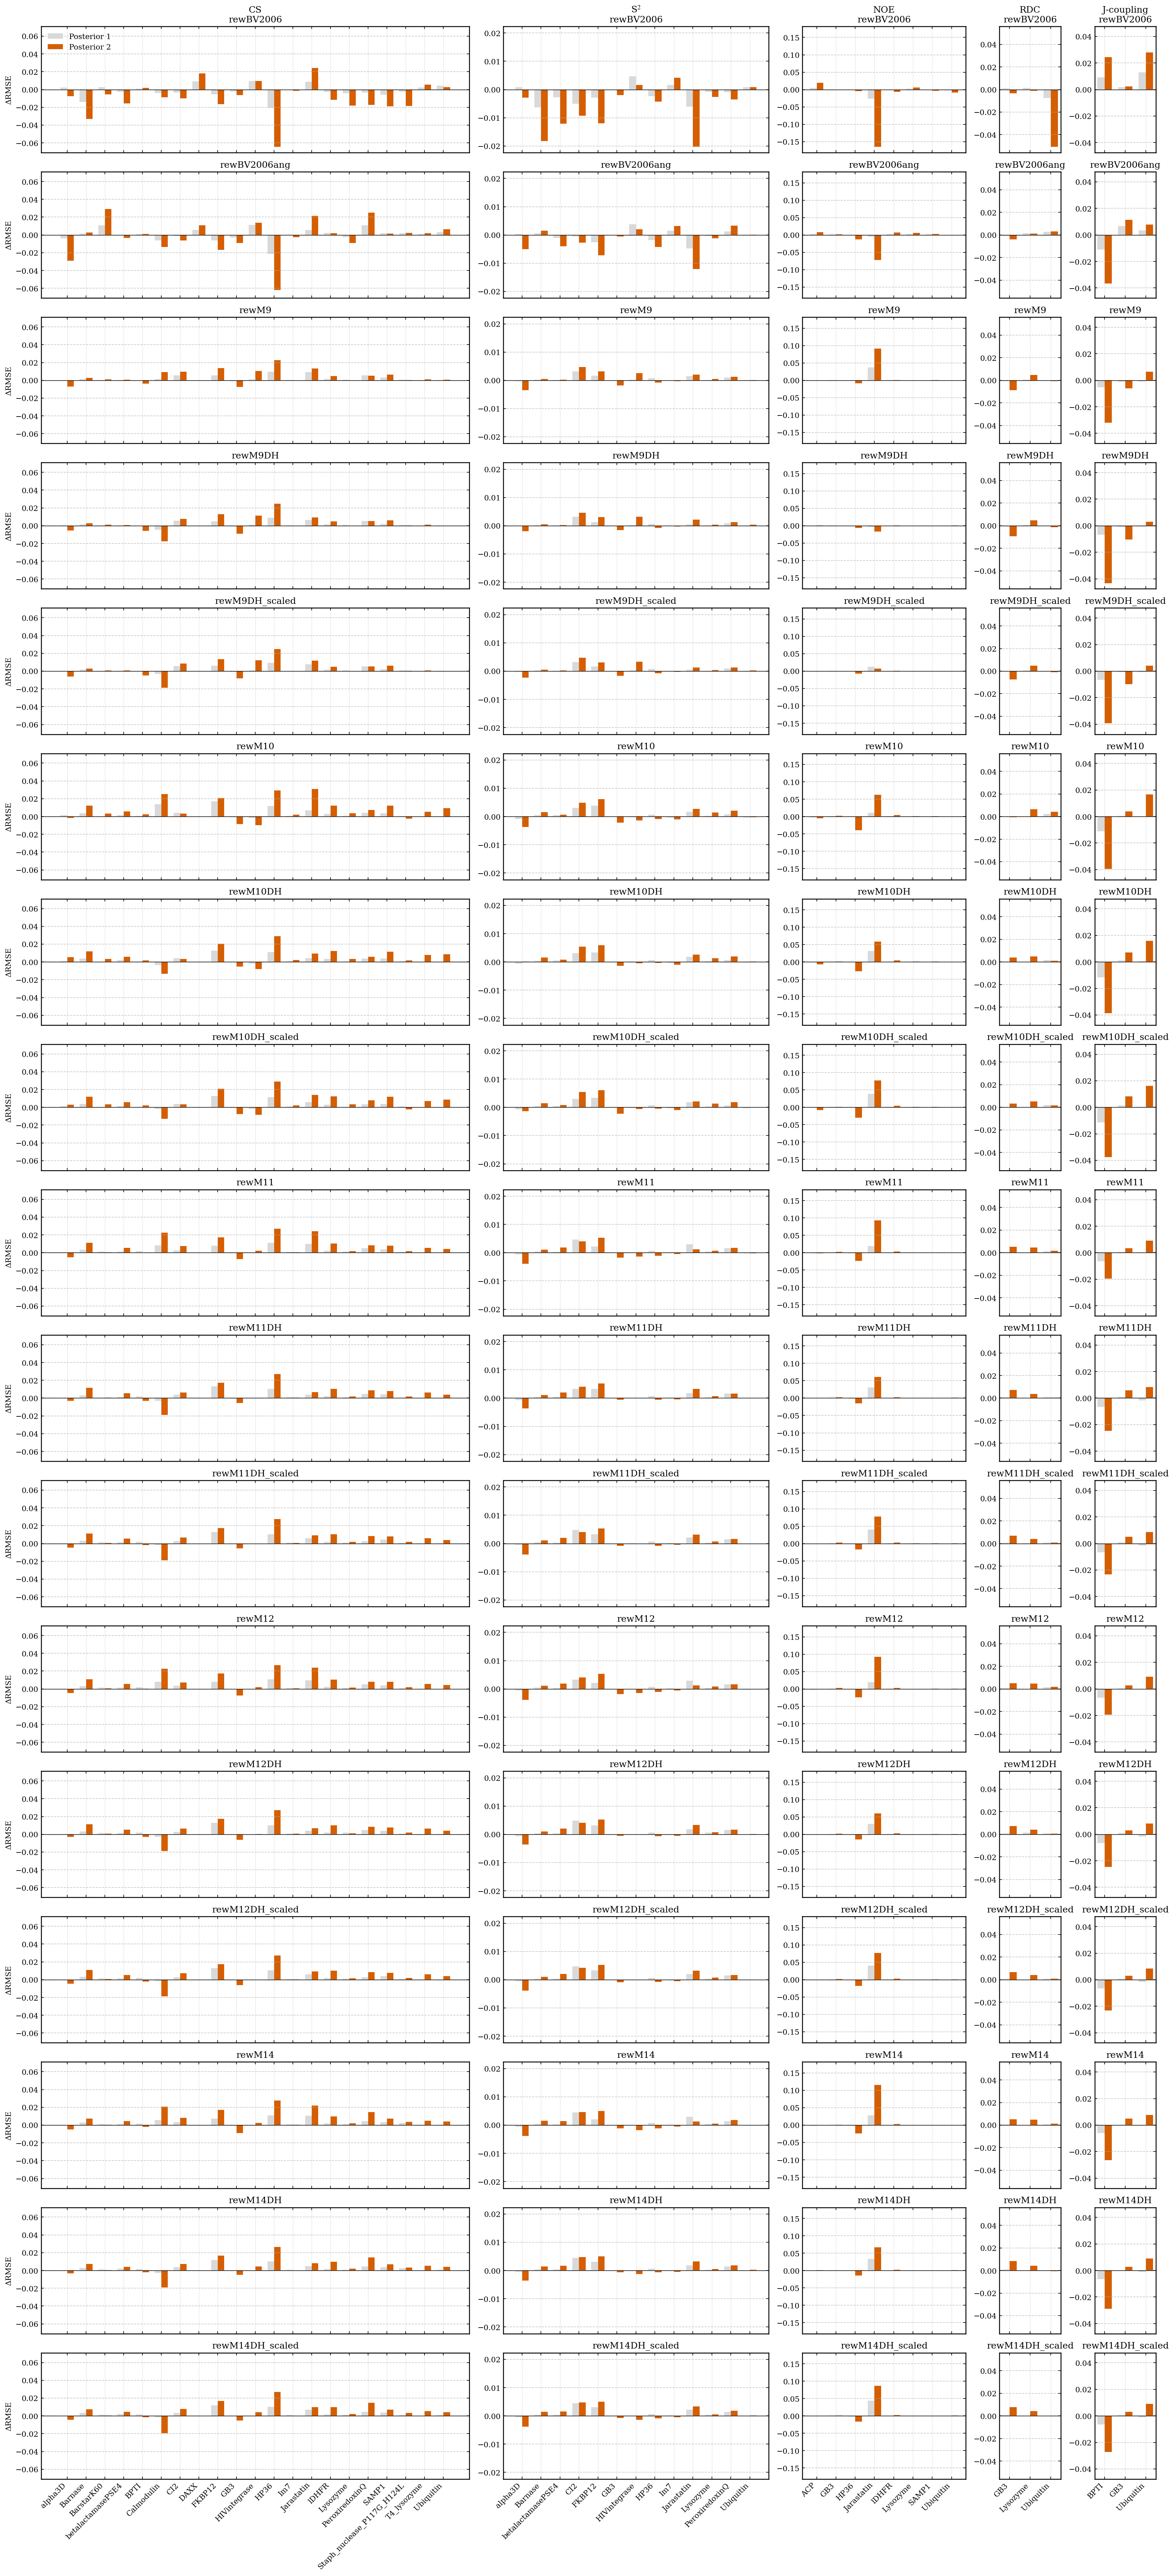

In [3]:
# summary with posterior 1 (elbow) and posterior 2 (final wopt with phi > 0.10)



# ---------------------------------------------------------
# Lists
# ---------------------------------------------------------
datatypes = ['CS', 'S$^2$', 'NOE', 'RDC', 'J-coupling']
dataname = ['CS', 'S2', 'NOE', 'RDC', 'Jcoupling']
directories = ['CS_analyses', 'S2_analyses_nonblockHDXrew', 'NOE_analyses',
               'RDC_analyses', 'Jcoupling_analyses']


# ---------------------------------------------------------
# Compute ΔRMSE or ΔQ for each datatype
# ---------------------------------------------------------
all_df = {}

for dtype, dname, ddir, prot_list in zip(datatypes, dataname, directories, proteins):

    rows = []

    for model in models:
        for prot in prot_list:

            if 'BV' in model:
                wopt_array = np.load(f"../../MD_DATA/{prot}/{model}/wopt_array.npy")
                wopt = np.load(f"../../MD_DATA/{prot}/{model}/wopt.npy")
                wopt_elbow = np.load(f"../../MD_DATA/{prot}/{model}/wopt_elbow.npy")
                rewdata = np.loadtxt(f"../../MD_DATA/{prot}/{model}/reweighting_chi2_phi_theta.txt")
                chi2, phi, thetas = rewdata[0, :], rewdata[1, :], rewdata[2, :]
            else:
                wopt_array = np.load(f"../../MD_DATA/{prot}/{model}/log_lambda_wopt_array.npy")
                wopt = np.load(f"../../MD_DATA/{prot}/{model}/log_lambda_wopt.npy")
                wopt_elbow = np.load(f"../../MD_DATA/{prot}/{model}/log_lambda_wopt_elbow.npy")
                rewdata = np.loadtxt(f"../../MD_DATA/{prot}/{model}/log_lambda_reweighting_chi2_phi_theta.txt")
                chi2, phi, thetas = rewdata[0, :], rewdata[1, :], rewdata[2, :]

            wopt_idx = np.where(wopt_array == wopt)[0][0]
            wopt_elbow_idx = np.where(wopt_array == wopt_elbow)[0][0]

            phi_elbow = phi[wopt_elbow_idx]

            if dname == 'S2':
                file = f"{ddir}/{prot}_{model}_{dname}_validation_1xTAUR.csv"
            else:
                file = f"{ddir}/{prot}_{model}_{dname}_validation.csv"

            dat = pd.read_csv(file)

            metric = "Q" if dname == "RDC" else "RMSE"

            if dtype == "J-coupling":
                col = f"J_{metric}"
            else:
                col = f"{dname}_{metric}"

            cv_phi = np.array(dat['Neff'])
            diff = np.abs(cv_phi - phi_elbow)
            cv_elbow_index = np.where(diff==np.min(diff))[0][0]
            prior = dat[col].iloc[0]
            post1 = dat[col].iloc[cv_elbow_index]
            post2 = dat[col].iloc[-1]

            rows.append({
                "Model": model,
                "Protein": prot,
                "Posterior 1": prior - post1,
                "Posterior 2": prior - post2,
                "metric": metric
            })

    all_df[dname] = pd.DataFrame(rows)

# ---------------------------------------------------------
# Figure with variable column widths
# ---------------------------------------------------------
n_models = len(models)
n_types  = len(datatypes)

width_ratios = [len(p) for p in proteins]  # each datatype column width proportional to protein count

fig, axes = plt.subplots(
    n_models, n_types,
    figsize=(sum(width_ratios) * 0.45, n_models * 2.8),
    gridspec_kw={"width_ratios": width_ratios},
    sharey=False
)

axes = np.atleast_2d(axes)

# ---------------------------------------------------------
# Fill subplots
# ---------------------------------------------------------
for c, (dtype, dname, prot_list) in enumerate(zip(datatypes, dataname, proteins)):

    df = all_df[dname]
    metric = df["metric"].iloc[0]
    ylabel = f"Δ{metric}"

    x = np.arange(len(prot_list))
    width = 0.35

    # -------- Symmetric y-range for this datatype --------
    raw_min = df[["Posterior 1", "Posterior 2"]].min().min()
    raw_max = df[["Posterior 1", "Posterior 2"]].max().max()
    max_abs = max(abs(raw_min), abs(raw_max)) * 1.1
    ymin, ymax = -max_abs, max_abs

    for r, model in enumerate(models):

        ax = axes[r, c]
        sub = df[df["Model"] == model]

        # Bars
        ax.bar(x - width/2, sub["Posterior 1"], width, color="#D9D9D9", label = 'Posterior 1')
        ax.bar(x + width/2, sub["Posterior 2"], width, color="#D55E00", label = 'Posterior 2')

        ax.axhline(0, color="black", linewidth=0.7)
        ax.set_ylim(ymin, ymax)

        # Grid for all rows
        ax.set_xticks(x)
        ax.grid(axis='x', linestyle='--', linewidth=0.4)

        # Only show tick labels on bottom row
        if r == n_models - 1:
            ax.set_xticklabels(prot_list, rotation=45, ha='right')
        else:
            ax.set_xticklabels([])

        # Titles
        avg_post2 = sub["Posterior 2"].mean()
        avg_post1   = sub["Posterior 1"].mean()
        ax.set_title(model)
        if r == 0:
            ax.set_title(f"{dtype}\n{model}")

        # Y-label only once per row (left column)
        if c == 0:
            ax.set_ylabel(ylabel)

        # Legend once
        if r == 0 and c == 0:
            ax.legend(loc="upper left")

plt.tight_layout()
plt.savefig(outpath+'Folded_Proteins_Crossvalidation.pdf', dpi=300)


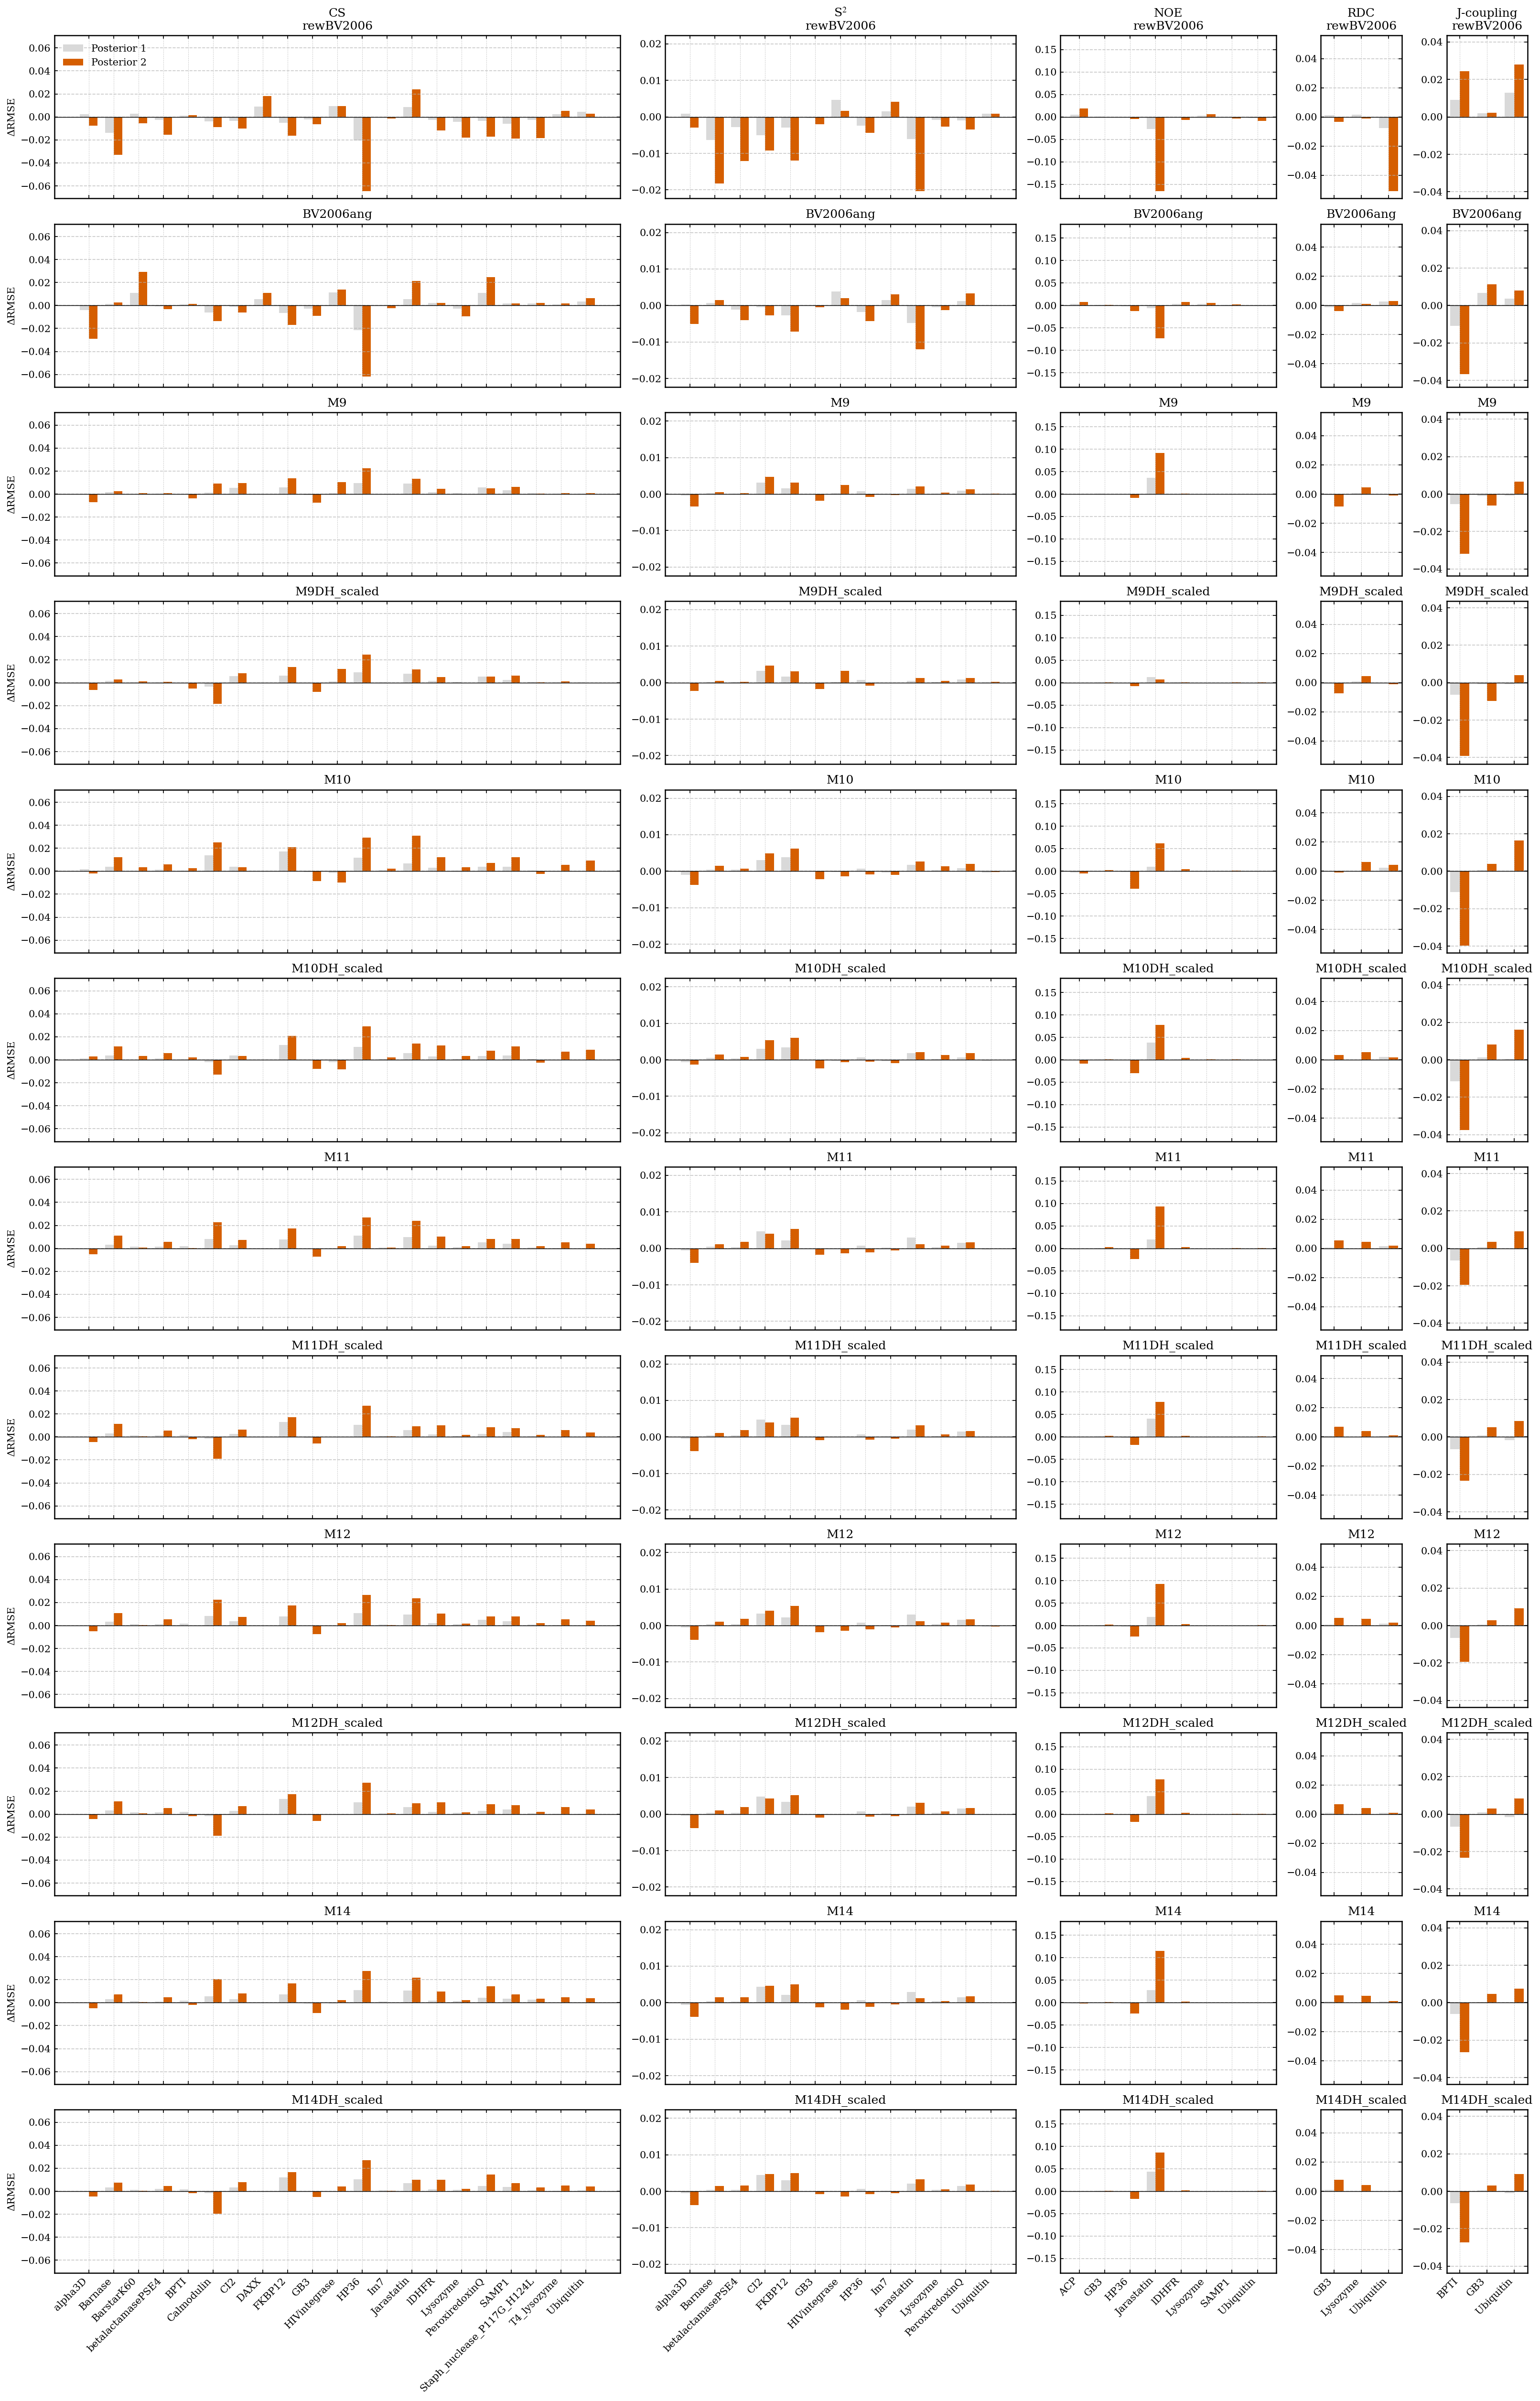

In [4]:
# summary with posterior 1 (elbow) and posterior 2 (final wopt with phi > 0.10)

models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH_scaled', 
          'rewM10', 'rewM10DH_scaled', 'rewM11', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH_scaled', 'rewM14', 'rewM14DH_scaled']

# ---------------------------------------------------------
# Lists
# ---------------------------------------------------------
datatypes = ['CS', 'S$^2$', 'NOE', 'RDC', 'J-coupling']
dataname = ['CS', 'S2', 'NOE', 'RDC', 'Jcoupling']
directories = ['CS_analyses', 'S2_analyses_nonblockHDXrew', 'NOE_analyses',
               'RDC_analyses', 'Jcoupling_analyses']


# ---------------------------------------------------------
# Compute ΔRMSE or ΔQ for each datatype
# ---------------------------------------------------------
all_df = {}

for dtype, dname, ddir, prot_list in zip(datatypes, dataname, directories, proteins):

    rows = []

    for model in models:
        for prot in prot_list:

            if 'BV' in model:
                wopt_array = np.load(f"../../MD_DATA/{prot}/{model}/wopt_array.npy")
                wopt = np.load(f"../../MD_DATA/{prot}/{model}/wopt.npy")
                wopt_elbow = np.load(f"../../MD_DATA/{prot}/{model}/wopt_elbow.npy")
                rewdata = np.loadtxt(f"../../MD_DATA/{prot}/{model}/reweighting_chi2_phi_theta.txt")
                chi2, phi, thetas = rewdata[0, :], rewdata[1, :], rewdata[2, :]
            else:
                wopt_array = np.load(f"../../MD_DATA/{prot}/{model}/log_lambda_wopt_array.npy")
                wopt = np.load(f"../../MD_DATA/{prot}/{model}/log_lambda_wopt.npy")
                wopt_elbow = np.load(f"../../MD_DATA/{prot}/{model}/log_lambda_wopt_elbow.npy")
                rewdata = np.loadtxt(f"../../MD_DATA/{prot}/{model}/log_lambda_reweighting_chi2_phi_theta.txt")
                chi2, phi, thetas = rewdata[0, :], rewdata[1, :], rewdata[2, :]

            wopt_idx = np.where(wopt_array == wopt)[0][0]
            wopt_elbow_idx = np.where(wopt_array == wopt_elbow)[0][0]

            phi_elbow = phi[wopt_elbow_idx]

            if dname == 'S2':
                file = f"{ddir}/{prot}_{model}_{dname}_validation_1xTAUR.csv"
            else:
                file = f"{ddir}/{prot}_{model}_{dname}_validation.csv"

            dat = pd.read_csv(file)

            metric = "Q" if dname == "RDC" else "RMSE"

            if dtype == "J-coupling":
                col = f"J_{metric}"
            else:
                col = f"{dname}_{metric}"

            cv_phi = np.array(dat['Neff'])
            diff = np.abs(cv_phi - phi_elbow)
            cv_elbow_index = np.where(diff==np.min(diff))[0][0]
            prior = dat[col].iloc[0]
            post1 = dat[col].iloc[cv_elbow_index]
            post2 = dat[col].iloc[-1]

            rows.append({
                "Model": model,
                "Protein": prot,
                "Posterior 1": prior - post1,
                "Posterior 2": prior - post2,
                "metric": metric
            })

    all_df[dname] = pd.DataFrame(rows)

# ---------------------------------------------------------
# Figure with variable column widths
# ---------------------------------------------------------
n_models = len(models)
n_types  = len(datatypes)

width_ratios = [len(p) for p in proteins]  # each datatype column width proportional to protein count

fig, axes = plt.subplots(
    n_models, n_types,
    figsize=(sum(width_ratios) * 0.45, n_models * 2.8),
    gridspec_kw={"width_ratios": width_ratios},
    sharey=False
)

axes = np.atleast_2d(axes)

# ---------------------------------------------------------
# Fill subplots
# ---------------------------------------------------------
for c, (dtype, dname, prot_list) in enumerate(zip(datatypes, dataname, proteins)):

    df = all_df[dname]
    metric = df["metric"].iloc[0]
    ylabel = f"Δ{metric}"

    x = np.arange(len(prot_list))
    width = 0.35

    # -------- Symmetric y-range for this datatype --------
    raw_min = df[["Posterior 1", "Posterior 2"]].min().min()
    raw_max = df[["Posterior 1", "Posterior 2"]].max().max()
    max_abs = max(abs(raw_min), abs(raw_max)) * 1.1
    ymin, ymax = -max_abs, max_abs

    for r, model in enumerate(models):

        ax = axes[r, c]
        sub = df[df["Model"] == model]

        # Bars
        ax.bar(x - width/2, sub["Posterior 1"], width, color="#D9D9D9", label = 'Posterior 1')
        ax.bar(x + width/2, sub["Posterior 2"], width, color="#D55E00", label = 'Posterior 2')

        ax.axhline(0, color="black", linewidth=0.7)
        ax.set_ylim(ymin, ymax)

        # Grid for all rows
        ax.set_xticks(x)
        ax.grid(axis='x', linestyle='--', linewidth=0.4)

        # Only show tick labels on bottom row
        if r == n_models - 1:
            ax.set_xticklabels(prot_list, rotation=45, ha='right')
        else:
            ax.set_xticklabels([])

        # Titles
        avg_post2 = sub["Posterior 2"].mean()
        avg_post1   = sub["Posterior 1"].mean()
        ax.set_title(model[3:])  # remove 'rew' prefix for title
        if r == 0:
            ax.set_title(f"{dtype}\n{model}")

        # Y-label only once per row (left column)
        if c == 0:
            ax.set_ylabel(ylabel)

        # Legend once
        if r == 0 and c == 0:
            ax.legend(loc="upper left")

plt.tight_layout()
plt.savefig(outpath+'Folded_Proteins_Crossvalidation_notall.pdf', dpi=300)



Maximum absolute change for each datatype:
Dataname
CS           0.064506
Jcoupling    0.043263
NOE          0.165224
RDC          0.050821
S2           0.020312
Name: Maximum absolute change, dtype: float64

Normalised model scores:
          Model   Posterior  Normalised change
      rewBV2006 Posterior 1          -0.023099
      rewBV2006 Posterior 2          -0.161610
   rewBV2006ang Posterior 1           0.001653
   rewBV2006ang Posterior 2          -0.054364
          rewM9 Posterior 1           0.024627
          rewM9 Posterior 2           0.028901
        rewM9DH Posterior 1           0.014239
        rewM9DH Posterior 2          -0.002010
 rewM9DH_scaled Posterior 1           0.017876
 rewM9DH_scaled Posterior 2           0.004606
         rewM10 Posterior 1           0.029659
         rewM10 Posterior 2           0.061192
       rewM10DH Posterior 1           0.024374
       rewM10DH Posterior 2           0.054966
rewM10DH_scaled Posterior 1           0.025930
rewM10DH_scal

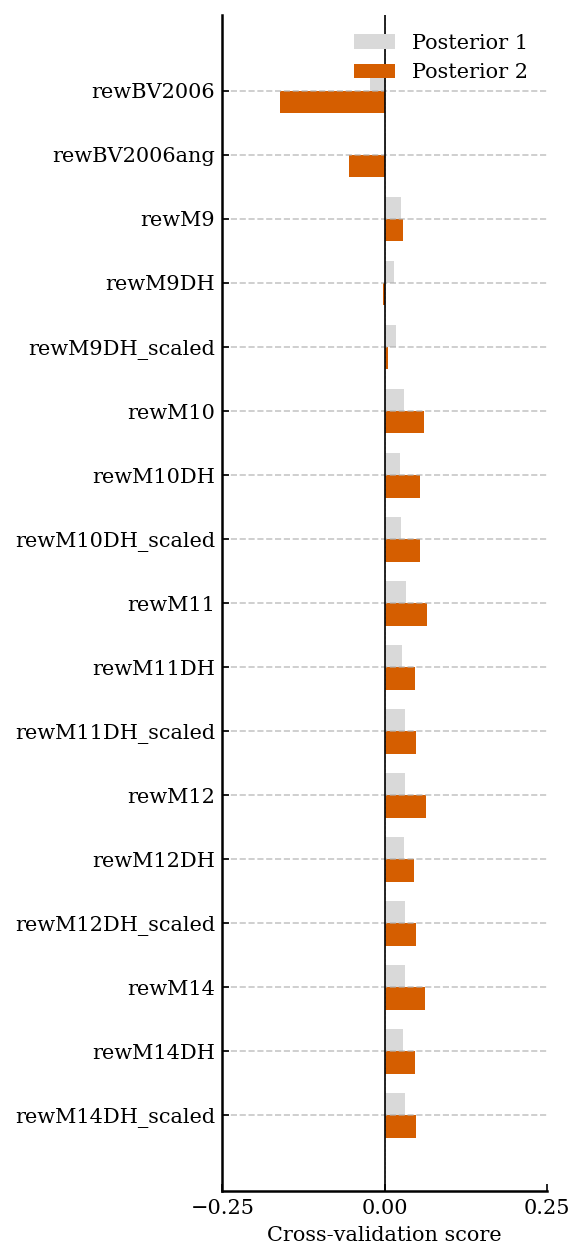

In [5]:

# ---------------------------------------------------------
# Lists
# ---------------------------------------------------------
datatypes = ['CS', 'S$^2$', 'NOE', 'RDC', 'J-coupling']
dataname = ['CS', 'S2', 'NOE', 'RDC', 'Jcoupling']
directories = ['CS_analyses', 'S2_analyses_nonblockHDXrew', 'NOE_analyses', 'RDC_analyses', 'Jcoupling_analyses']

models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled', 
          'rewM10', 'rewM10DH', 'rewM10DH_scaled', 'rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH', 'rewM12DH_scaled', 'rewM14', 'rewM14DH', 'rewM14DH_scaled']

# ---------------------------------------------------------
# Calculate prior − all posteriors and identify Posterior 1/2
# ---------------------------------------------------------
all_rows = []
selected_rows = []

for dtype, dname, ddir, prot_list in zip(datatypes, dataname, directories, proteins):
    for model in models:
        for prot in prot_list:

            if 'BV' in model:
                wopt_array = np.load(f"../../MD_DATA/{prot}/{model}/wopt_array.npy")
                wopt_elbow = np.load(f"../../MD_DATA/{prot}/{model}/wopt_elbow.npy")
                rewdata = np.loadtxt(f"../../MD_DATA/{prot}/{model}/reweighting_chi2_phi_theta.txt")
            else:
                wopt_array = np.load(f"../../MD_DATA/{prot}/{model}/log_lambda_wopt_array.npy")
                wopt_elbow = np.load(f"../../MD_DATA/{prot}/{model}/log_lambda_wopt_elbow.npy")
                rewdata = np.loadtxt(f"../../MD_DATA/{prot}/{model}/log_lambda_reweighting_chi2_phi_theta.txt")

            phi = rewdata[1, :]
            wopt_elbow_idx = np.where(wopt_array == wopt_elbow)[0][0]
            phi_elbow = phi[wopt_elbow_idx]

            file = f"{ddir}/{prot}_{model}_{dname}_validation_1xTAUR.csv" if dname == 'S2' else f"{ddir}/{prot}_{model}_{dname}_validation.csv"
            dat = pd.read_csv(file)

            metric = "Q" if dname == "RDC" else "RMSE"
            col = f"J_{metric}" if dtype == "J-coupling" else f"{dname}_{metric}"

            cv_phi = dat["Neff"].to_numpy()
            cv_elbow_idx = np.argmin(np.abs(cv_phi - phi_elbow))

            prior = dat[col].iloc[0]
            changes = prior - dat[col].iloc[1:].to_numpy()

            for posterior_idx, change in enumerate(changes, start=1):
                all_rows.append({"Datatype": dtype, "Dataname": dname, "Model": model, "Protein": prot, "Posterior index": posterior_idx, "Change": change})

            selected_rows.append({"Datatype": dtype, "Dataname": dname, "Model": model, "Protein": prot, "Posterior": "Posterior 1", "Change": prior - dat[col].iloc[cv_elbow_idx]})
            selected_rows.append({"Datatype": dtype, "Dataname": dname, "Model": model, "Protein": prot, "Posterior": "Posterior 2", "Change": prior - dat[col].iloc[-1]})

all_changes = pd.DataFrame(all_rows)
selected_changes = pd.DataFrame(selected_rows)

# ---------------------------------------------------------
# Maximum absolute change across all posterior points
# ---------------------------------------------------------
max_abs_change = all_changes.groupby("Dataname")["Change"].apply(lambda x: np.max(np.abs(x))).rename("Maximum absolute change")

selected_changes = selected_changes.merge(max_abs_change, on="Dataname")
selected_changes["Normalised change"] = selected_changes["Change"] / selected_changes["Maximum absolute change"]

# ---------------------------------------------------------
# Average across proteins and datatypes for each model
# ---------------------------------------------------------
model_scores = selected_changes.groupby(["Model", "Posterior"], as_index=False)["Normalised change"].mean()
model_scores["Model"] = pd.Categorical(model_scores["Model"], categories=models, ordered=True)
model_scores = model_scores.sort_values(["Model", "Posterior"])

print("\nMaximum absolute change for each datatype:")
print(max_abs_change)

print("\nNormalised model scores:")
print(model_scores.to_string(index=False))

# ---------------------------------------------------------
# Horizontal bar plot
# ---------------------------------------------------------
score_post1 = model_scores[model_scores["Posterior"] == "Posterior 1"].set_index("Model").reindex(models)["Normalised change"]
score_post2 = model_scores[model_scores["Posterior"] == "Posterior 2"].set_index("Model").reindex(models)["Normalised change"]

fig, ax = plt.subplots(figsize=(4, max(4, 0.5 * len(models))))

y = np.arange(len(models))
height = 0.35

ax.barh(y - height / 2, score_post1, height, color="#D9D9D9", label="Posterior 1")
ax.barh(y + height / 2, score_post2, height, color="#D55E00", label="Posterior 2")

ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(y)
ax.set_yticklabels(models)
ax.set_xlim(-0.25, 0.25)
ax.set_xticks([-0.25, 0, 0.25])
ax.set_xlabel("Cross-validation score")
ax.invert_yaxis()
ax.grid(axis="x", linestyle="--", linewidth=0.4)
ax.legend()

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", which="both", top=False, right=False)

plt.tight_layout()
plt.savefig(outpath + "Folded_Proteins_Normalised_Crossvalidation_Score_all.pdf", dpi=300, bbox_inches="tight")
plt.show()


Maximum absolute change for each datatype:
Dataname
CS           0.064506
Jcoupling    0.039612
NOE          0.165224
RDC          0.050821
S2           0.020312
Name: Maximum absolute change, dtype: float64

Normalised model scores:
          Model   Posterior  Normalised change
      rewBV2006 Posterior 1          -0.022045
      rewBV2006 Posterior 2          -0.159185
   rewBV2006ang Posterior 1           0.001621
   rewBV2006ang Posterior 2          -0.055138
          rewM9 Posterior 1           0.024309
          rewM9 Posterior 2           0.027503
 rewM9DH_scaled Posterior 1           0.017510
 rewM9DH_scaled Posterior 2           0.002617
         rewM10 Posterior 1           0.029200
         rewM10 Posterior 2           0.060345
rewM10DH_scaled Posterior 1           0.025503
rewM10DH_scaled Posterior 2           0.053752
         rewM11 Posterior 1           0.032297
         rewM11 Posterior 2           0.064827
rewM11DH_scaled Posterior 1           0.031288
rewM11DH_scal

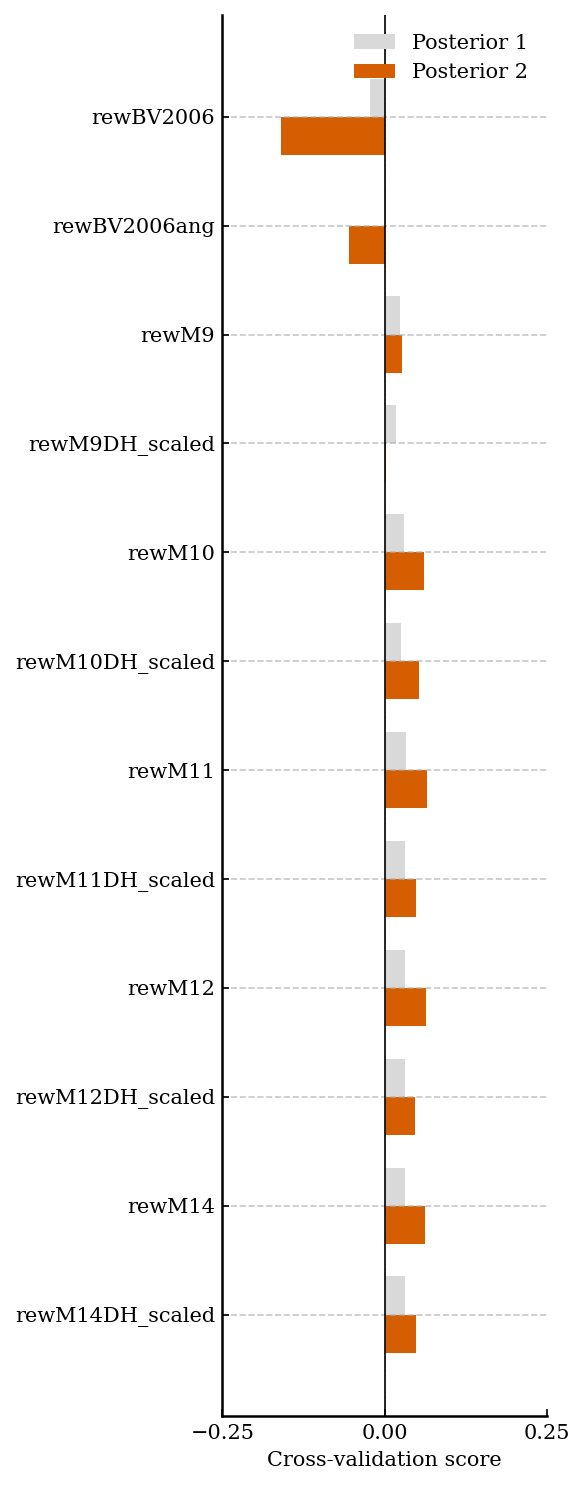

In [8]:

models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH_scaled', 
          'rewM10', 'rewM10DH_scaled', 'rewM11', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH_scaled', 'rewM14', 'rewM14DH_scaled']

# ---------------------------------------------------------
# Lists
# ---------------------------------------------------------
datatypes = ['CS', 'S$^2$', 'NOE', 'RDC', 'J-coupling']
dataname = ['CS', 'S2', 'NOE', 'RDC', 'Jcoupling']
directories = ['CS_analyses', 'S2_analyses_nonblockHDXrew', 'NOE_analyses', 'RDC_analyses', 'Jcoupling_analyses']

# ---------------------------------------------------------
# Calculate prior − all posteriors and identify Posterior 1/2
# ---------------------------------------------------------
all_rows = []
selected_rows = []

for dtype, dname, ddir, prot_list in zip(datatypes, dataname, directories, proteins):
    for model in models:
        for prot in prot_list:

            if 'BV' in model:
                wopt_array = np.load(f"../../MD_DATA/{prot}/{model}/wopt_array.npy")
                wopt_elbow = np.load(f"../../MD_DATA/{prot}/{model}/wopt_elbow.npy")
                rewdata = np.loadtxt(f"../../MD_DATA/{prot}/{model}/reweighting_chi2_phi_theta.txt")
            else:
                wopt_array = np.load(f"../../MD_DATA/{prot}/{model}/log_lambda_wopt_array.npy")
                wopt_elbow = np.load(f"../../MD_DATA/{prot}/{model}/log_lambda_wopt_elbow.npy")
                rewdata = np.loadtxt(f"../../MD_DATA/{prot}/{model}/log_lambda_reweighting_chi2_phi_theta.txt")

            phi = rewdata[1, :]
            wopt_elbow_idx = np.where(wopt_array == wopt_elbow)[0][0]
            phi_elbow = phi[wopt_elbow_idx]

            file = f"{ddir}/{prot}_{model}_{dname}_validation_1xTAUR.csv" if dname == 'S2' else f"{ddir}/{prot}_{model}_{dname}_validation.csv"
            dat = pd.read_csv(file)

            metric = "Q" if dname == "RDC" else "RMSE"
            col = f"J_{metric}" if dtype == "J-coupling" else f"{dname}_{metric}"

            cv_phi = dat["Neff"].to_numpy()
            cv_elbow_idx = np.argmin(np.abs(cv_phi - phi_elbow))

            prior = dat[col].iloc[0]
            changes = prior - dat[col].iloc[1:].to_numpy()

            for posterior_idx, change in enumerate(changes, start=1):
                all_rows.append({"Datatype": dtype, "Dataname": dname, "Model": model, "Protein": prot, "Posterior index": posterior_idx, "Change": change})

            selected_rows.append({"Datatype": dtype, "Dataname": dname, "Model": model, "Protein": prot, "Posterior": "Posterior 1", "Change": prior - dat[col].iloc[cv_elbow_idx]})
            selected_rows.append({"Datatype": dtype, "Dataname": dname, "Model": model, "Protein": prot, "Posterior": "Posterior 2", "Change": prior - dat[col].iloc[-1]})

all_changes = pd.DataFrame(all_rows)
selected_changes = pd.DataFrame(selected_rows)

# ---------------------------------------------------------
# Maximum absolute change across all posterior points
# ---------------------------------------------------------
max_abs_change = all_changes.groupby("Dataname")["Change"].apply(lambda x: np.max(np.abs(x))).rename("Maximum absolute change")

selected_changes = selected_changes.merge(max_abs_change, on="Dataname")
selected_changes["Normalised change"] = selected_changes["Change"] / selected_changes["Maximum absolute change"]

# ---------------------------------------------------------
# Average across proteins and datatypes for each model
# ---------------------------------------------------------
model_scores = selected_changes.groupby(["Model", "Posterior"], as_index=False)["Normalised change"].mean()
model_scores["Model"] = pd.Categorical(model_scores["Model"], categories=models, ordered=True)
model_scores = model_scores.sort_values(["Model", "Posterior"])

print("\nMaximum absolute change for each datatype:")
print(max_abs_change)

print("\nNormalised model scores:")
print(model_scores.to_string(index=False))

# ---------------------------------------------------------
# Horizontal bar plot
# ---------------------------------------------------------
score_post1 = model_scores[model_scores["Posterior"] == "Posterior 1"].set_index("Model").reindex(models)["Normalised change"]
score_post2 = model_scores[model_scores["Posterior"] == "Posterior 2"].set_index("Model").reindex(models)["Normalised change"]

fig, ax = plt.subplots(figsize=(4, 10))

y = np.arange(len(models))
height = 0.35

ax.barh(y - height / 2, score_post1, height, color="#D9D9D9", label="Posterior 1")
ax.barh(y + height / 2, score_post2, height, color="#D55E00", label="Posterior 2")

ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(y)
ax.set_yticklabels(models)
ax.set_xlim(-0.25, 0.25)
ax.set_xticks([-0.25, 0, 0.25])
ax.set_xlabel("Cross-validation score")
ax.invert_yaxis()
ax.grid(axis="x", linestyle="--", linewidth=0.4)
ax.legend()

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", which="both", top=False, right=False)

plt.tight_layout()
plt.savefig(outpath + "Folded_Proteins_Normalised_Crossvalidation_Score.pdf", dpi=300, bbox_inches="tight")
plt.show()


Fraction of proteins with cross-validation score < -0.1:
          Model   Posterior  Fraction worse than -0.1
      rewBV2006 Posterior 1                  0.227273
      rewBV2006 Posterior 2                  0.545455
   rewBV2006ang Posterior 1                  0.136364
   rewBV2006ang Posterior 2                  0.363636
          rewM9 Posterior 1                  0.000000
          rewM9 Posterior 2                  0.136364
        rewM9DH Posterior 1                  0.000000
        rewM9DH Posterior 2                  0.136364
 rewM9DH_scaled Posterior 1                  0.000000
 rewM9DH_scaled Posterior 2                  0.181818
         rewM10 Posterior 1                  0.045455
         rewM10 Posterior 2                  0.136364
       rewM10DH Posterior 1                  0.045455
       rewM10DH Posterior 2                  0.090909
rewM10DH_scaled Posterior 1                  0.045455
rewM10DH_scaled Posterior 2                  0.090909
         rewM11 Posterio

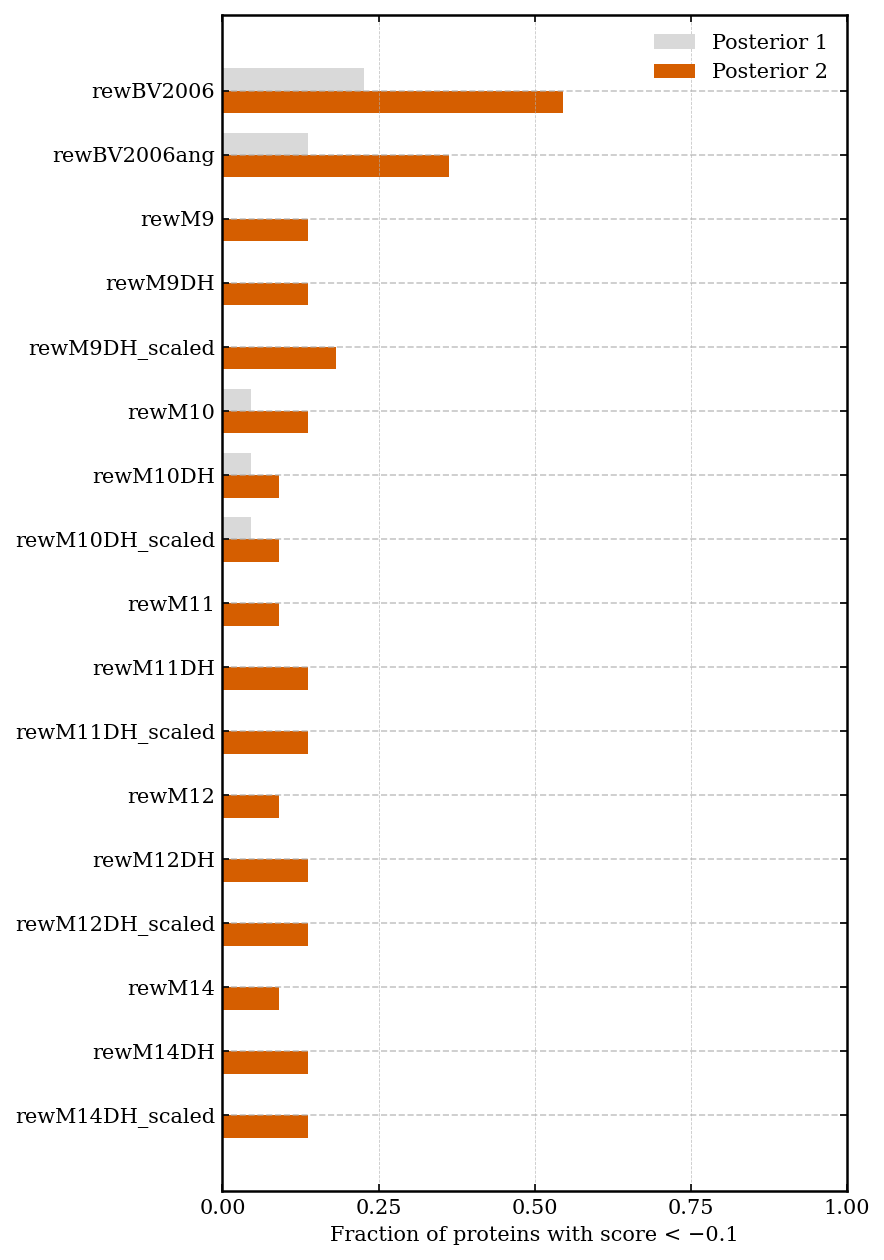

In [ ]:
models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled', 
          'rewM10', 'rewM10DH', 'rewM10DH_scaled', 'rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH', 'rewM12DH_scaled', 'rewM14', 'rewM14DH', 'rewM14DH_scaled']

# ---------------------------------------------------------
# Fraction of proteins with cross-validation score < -0.1
# ---------------------------------------------------------
protein_scores = selected_changes.groupby(["Model", "Protein", "Posterior"], as_index=False)["Normalised change"].mean()
fraction_worse = protein_scores.groupby(["Model", "Posterior"])["Normalised change"].apply(lambda x: np.mean(x < -0.1)).reset_index(name="Fraction worse than -0.1")

fraction_worse["Model"] = pd.Categorical(fraction_worse["Model"], categories=models, ordered=True)
fraction_worse = fraction_worse.sort_values(["Model", "Posterior"])

fraction_post1 = fraction_worse[fraction_worse["Posterior"] == "Posterior 1"].set_index("Model").reindex(models)["Fraction worse than -0.1"]
fraction_post2 = fraction_worse[fraction_worse["Posterior"] == "Posterior 2"].set_index("Model").reindex(models)["Fraction worse than -0.1"]

print("\nFraction of proteins with cross-validation score < -0.1:")
print(fraction_worse.to_string(index=False))

fig, ax = plt.subplots(figsize=(6, max(4, 0.5 * len(models))))

y = np.arange(len(models))
height = 0.35

ax.barh(y - height / 2, fraction_post1, height, color="#D9D9D9", label="Posterior 1")
ax.barh(y + height / 2, fraction_post2, height, color="#D55E00", label="Posterior 2")

ax.set_yticks(y)
ax.set_yticklabels(models)
ax.set_xlim(0, 1)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
ax.set_xlabel("Fraction of proteins with score < −0.1")
ax.invert_yaxis()
ax.grid(axis="x", linestyle="--", linewidth=0.4)
ax.legend()

plt.tight_layout()
plt.savefig(outpath + "Folded_Proteins_Fraction_Worse_Than_Minus_0.1.pdf", dpi=300, bbox_inches="tight")
plt.show()